# Modèle prédictif de la réussite
## 1. Définition de la cible et des variables explicatives

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

sns.set_theme()
df = pd.read_csv("../data/etudiants_propre.csv")

# Variable cible : 1 = Réussi, 0 = Échec
y = (df["resultat"] == "Réussi").astype(int)

# Variables explicatives : on exclut moyenne, note_cc et note_examen
X = df[["age", "sexe", "filiere", "niveau", "heures_etude", "absences",
        "internet", "reseaux_sociaux", "participation_td"]]
X = pd.get_dummies(X, drop_first=True)

print(X.shape)
print(y.value_counts())

(500, 12)
resultat
0    313
1    187
Name: count, dtype: int64


## 2. Séparation apprentissage / test

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Apprentissage :", X_train.shape[0], "étudiants")
print("Test          :", X_test.shape[0], "étudiants")

Apprentissage : 400 étudiants
Test          : 100 étudiants


## 3. Entraînement du modèle (régression logistique)

In [3]:
# Mise à la même échelle des variables (moyenne 0, écart-type 1)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

model = LogisticRegression(max_iter=1000)
model.fit(X_train_s, y_train)
print("Modèle entraîné sur", X_train_s.shape[0], "étudiants")

Modèle entraîné sur 400 étudiants


## 4. Évaluation sur les données de test

In [4]:
y_pred = model.predict(X_test_s)

print("Exactitude (accuracy) :", round(accuracy_score(y_test, y_pred), 2))
print("Référence (toujours prédire Échec) :", round((y_test == 0).mean(), 2))
print()
print("Matrice de confusion :")
print(confusion_matrix(y_test, y_pred))
print()
print(classification_report(y_test, y_pred, target_names=["Échec", "Réussi"]))

Exactitude (accuracy) : 0.68
Référence (toujours prédire Échec) : 0.63

Matrice de confusion :
[[50 13]
 [19 18]]

              precision    recall  f1-score   support

       Échec       0.72      0.79      0.76        63
      Réussi       0.58      0.49      0.53        37

    accuracy                           0.68       100
   macro avg       0.65      0.64      0.64       100
weighted avg       0.67      0.68      0.67       100



## 5. Matrice de confusion (figure)

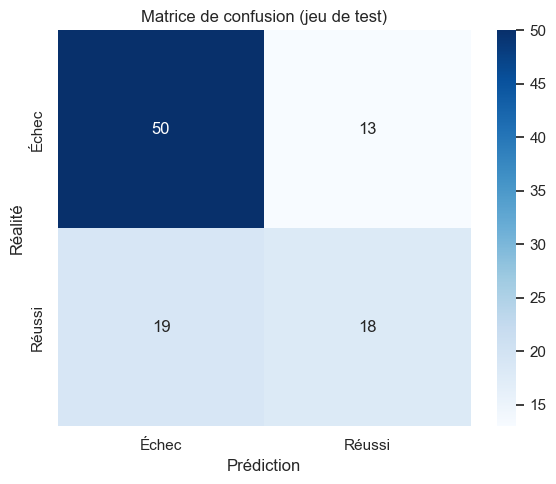

In [5]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Échec", "Réussi"], yticklabels=["Échec", "Réussi"])
plt.title("Matrice de confusion (jeu de test)")
plt.xlabel("Prédiction")
plt.ylabel("Réalité")
plt.tight_layout()
plt.savefig("../figures/matrice_confusion.png", dpi=150)
plt.show()

## 6. Variables les plus influentes

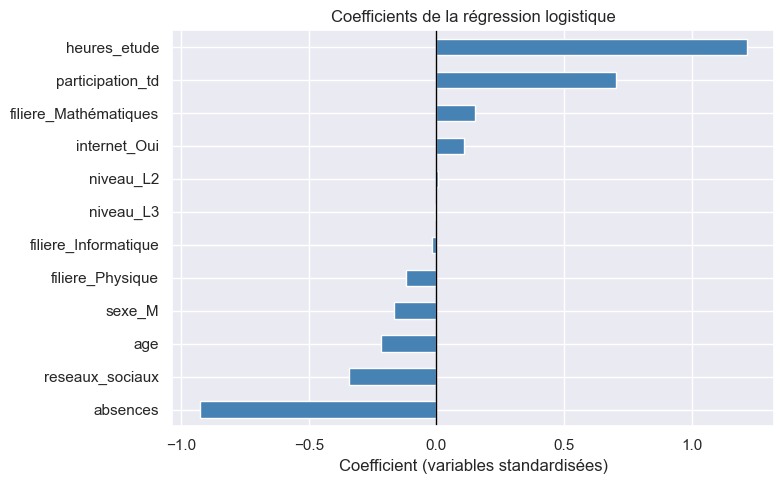

absences                -0.93
reseaux_sociaux         -0.34
age                     -0.22
sexe_M                  -0.16
filiere_Physique        -0.12
filiere_Informatique    -0.02
niveau_L3               -0.01
niveau_L2                0.00
internet_Oui             0.11
filiere_Mathématiques    0.15
participation_td         0.71
heures_etude             1.22
dtype: float64


In [6]:
coef = pd.Series(model.coef_[0], index=X.columns).sort_values()

plt.figure(figsize=(8, 5))
coef.plot(kind="barh", color="steelblue")
plt.axvline(0, color="black", linewidth=1)
plt.title("Coefficients de la régression logistique")
plt.xlabel("Coefficient (variables standardisées)")
plt.tight_layout()
plt.savefig("../figures/coefficients.png", dpi=150)
plt.show()

print(coef.round(2))

## 7. Validation croisée

In [7]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
scores = cross_val_score(pipe, X, y, cv=5, scoring="accuracy")

print("Exactitude sur 5 découpages :", scores.round(2))
print("Moyenne :", round(scores.mean(), 2))

Exactitude sur 5 découpages : [0.74 0.72 0.76 0.75 0.76]
Moyenne : 0.75


## 8. Analyse des erreurs

In [8]:
test = df.loc[X_test.index, ["moyenne", "heures_etude", "absences"]].copy()
test["reel"] = y_test
test["pred"] = y_pred
test["erreur"] = test["reel"] != test["pred"]

print("Moyenne des étudiants bien classés :", round(test[~test["erreur"]]["moyenne"].mean(), 2))
print("Moyenne des étudiants mal classés  :", round(test[test["erreur"]]["moyenne"].mean(), 2))
proches = test[test["erreur"]]["moyenne"].between(8, 12).mean()
print("Part des erreurs avec une moyenne entre 8 et 12 :", round(proches, 2))

Moyenne des étudiants bien classés : 8.95
Moyenne des étudiants mal classés  : 9.93
Part des erreurs avec une moyenne entre 8 et 12 : 0.84


## Conclusion
Une régression logistique a été entraînée sur 400 étudiants et testée sur 100 pour prédire la réussite. Les variables `moyenne`, `note_cc` et `note_examen` ont été exclues, car la réussite se déduit directement de la moyenne.

Sur le jeu de test, le modèle atteint une exactitude de 0,68, contre 0,63 pour un modèle qui répondrait toujours « Échec ». La validation croisée à 5 groupes donne une exactitude moyenne de 0,75, ce qui montre que le premier résultat était plutôt pessimiste et que le modèle est stable. Il repère mieux les échecs (rappel de 0,79) que les réussites (rappel de 0,49).

Les variables les plus influentes sont les heures d'étude et la participation aux TD/TP (effet positif), puis les absences et le temps passé sur les réseaux sociaux (effet négatif). 84 % des erreurs concernent des étudiants dont la moyenne est entre 8 et 12, c'est-à-dire proches du seuil de 10.

Le modèle est limité par la petite taille des données (500 étudiants) et par leur caractère simulé : il ne dit rien de la réalité d'une université.